# Signal efficiency cutflow — all samples and all configured cuts
Run on LPC from top to bottom. No manually maintained sample list is needed: every sample in the efficiency histograms is included. The current configuration has cut0–cut7. Cut names are read from cuts.py without executing it; values and descriptions come from the existing Coffea output. Changing cuts.py does not recalculate an old Coffea file: regenerate that output after analysis changes.

Efficiency = summed numerator / summed denominator at each stage. This is an event-count combination, not an average across samples or a cross-section-weighted mixture. Binomial uncertainties assume unit-weight event counts. Integer checks do not prove that assumption. No outputs are saved automatically.


In [1]:
from pathlib import Path
from textwrap import fill
import ast
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from coffea import util
import hist.intervals

LPC_REPO = Path('/uscms/home/reshmar/nobackup/IDMe_Run3_Collab/CMSSW_13_0_13/src/iDMe')
f_sig = LPC_REPO / 'python_analysis/coffea/OptimizeSignalStudies/OptimizeSignalStudies.coffea'
cuts_file = LPC_REPO / 'python_analysis/thesis_plots/electron_xclean/cut_configs/cuts.py'
selected_year = 2022  # Plot label only; does not filter samples.

sig_histo = util.load(str(f_sig))[0]


In [2]:
# Read the cut names without importing or running the cut configuration.
tree = ast.parse(cuts_file.read_text())
cuts_to_plot = sorted(
    [node.name for node in tree.body
     if isinstance(node, ast.FunctionDef) and re.fullmatch(r'cut\d+', node.name)],
    key=lambda name: int(name[3:]),
)
if not cuts_to_plot:
    raise ValueError('No numbered cuts found in cuts.py.')

num_hist = sig_histo['eff_num']
den_hist = sig_histo['eff_den']
num_samples = set(num_hist.axes['samp'])
den_samples = set(den_hist.axes['samp'])
if num_samples != den_samples:
    raise ValueError(f'Sample lists differ. Numerator only: {num_samples-den_samples}; denominator only: {den_samples-num_samples}')
sample_names = sorted(den_samples)
if not sample_names:
    raise ValueError('No samples found.')
for variable, histogram in [('eff_num', num_hist), ('eff_den', den_hist)]:
    missing = set(cuts_to_plot) - set(histogram.axes['cut'])
    if missing:
        raise ValueError(f'{variable} is missing cuts {sorted(missing)}. Produce a Coffea file containing all configured stages.')

# Use the descriptions actually saved when the Coffea file was produced.
descriptions = {}
for cut in cuts_to_plot:
    description = str(sig_histo.get('cutDesc', {}).get(cut, '')).split('@')[0].strip()
    if not description:
        raise ValueError(f'No saved description for {cut}.')
    descriptions[cut] = description

print(f'Including ALL {len(sample_names)} samples in the efficiency histograms:')
print('\n'.join(sample_names))
print('\nConfigured cuts and saved descriptions:')
for cut in cuts_to_plot:
    print(f'{cut}: {descriptions[cut]}')


Including ALL 15 samples in the efficiency histograms:
sig_2022_Mchi-105p0_dMchi-10p0_ctau-100
sig_2022_Mchi-110p0_dMchi-20p0_ctau-100
sig_2022_Mchi-11p0_dMchi-2p0_ctau-100
sig_2022_Mchi-22p0_dMchi-4p0_ctau-100
sig_2022_Mchi-33p0_dMchi-6p0_ctau-100
sig_2022_Mchi-44p0_dMchi-8p0_ctau-100
sig_2022_Mchi-55p0_dMchi-10p0_ctau-100
sig_2022_Mchi-63p0_dMchi-6p0_ctau-100
sig_2022_Mchi-66p0_dMchi-12p0_ctau-100
sig_2022_Mchi-73p5_dMchi-7p0_ctau-100
sig_2022_Mchi-77p0_dMchi-14p0_ctau-100
sig_2022_Mchi-84p0_dMchi-8p0_ctau-100
sig_2022_Mchi-88p0_dMchi-16p0_ctau-100
sig_2022_Mchi-94p5_dMchi-9p0_ctau-100
sig_2022_Mchi-99p0_dMchi-18p0_ctau-100

Configured cuts and saved descriptions:
cut0: Good vertex none: All vertices
cut1: Good vertex default:  IDcut
cut2: Good vertex v1: IDcut & chi2
cut3: Good vertex v2: IDcut & chi2 & mass_lo_refit
cut4: Good vertex v3: IDcut & chi2 & mass_lo_refit & maxMiniIso
cut5: Good vertex v4: IDcut & chi2 & mass_lo_refit & maxMiniIso & mindxy_refit
cut6: Good vertex v5: IDc

In [3]:
sample_rows = []
cutflow_rows = []
for cut in cuts_to_plot:
    total_num, total_den = 0.0, 0.0
    for sample in sample_names:
        num = float(num_hist[{'samp': sample, 'cut': cut}].values().sum())
        den = float(den_hist[{'samp': sample, 'cut': cut}].values().sum())
        if not np.all(np.isfinite([num, den])) or not 0 <= num <= den:
            raise ValueError(f'Invalid counts: {sample}, {cut}: {num}/{den}')
        if not np.allclose([num, den], np.round([num, den]), rtol=0, atol=1e-6):
            raise ValueError('Expected integer event counts for binomial uncertainties.')
        sample_rows.append({'cut': cut, 'sample': sample, 'numerator': num, 'denominator': den})
        total_num += num
        total_den += den
    eff, low, high = np.nan, np.nan, np.nan
    if total_den > 0:
        eff = total_num / total_den
        unc = hist.intervals.ratio_uncertainty(np.array([total_num]), np.array([total_den]), 'efficiency')
        low, high = unc[:, 0]
    cutflow_rows.append({
        'cut': cut, 'description': descriptions[cut],
        'numerator': total_num, 'denominator': total_den,
        'efficiency (%)': 100 * eff,
        'uncertainty low (pp)': 100 * low,
        'uncertainty high (pp)': 100 * high,
    })

cutflow_df = pd.DataFrame(cutflow_rows)
sample_cut_df = pd.DataFrame(sample_rows)
print(cutflow_df.to_string(index=False))

# Check that the reference event population is unchanged for each sample.
den_table = sample_cut_df.pivot(index='sample', columns='cut', values='denominator')
changing = den_table.index[den_table.nunique(axis=1) > 1].tolist()
if changing:
    print('\nNOTE: denominator changes for these samples:', changing)
    print('These efficiencies use each stage’s denominator, not a fixed initial denominator.')
else:
    print('\nConfirmed: denominator unchanged at every cut for every sample.')

if np.any(np.diff(cutflow_df['numerator'].to_numpy()) > 0):
    print('NOTE: numerator increases at a stage. Check whether the selections are cumulative and the Coffea output matches your intended configuration.')

# Optional detailed check, without reprocessing histograms:
# print(sample_cut_df.to_string(index=False))


 cut                                                                                              description  numerator  denominator  efficiency (%)  uncertainty low (pp)  uncertainty high (pp)
cut0                                                                           Good vertex none: All vertices   403200.0    3694964.0       10.912150              0.016223               0.016244
cut1                                                                              Good vertex default:  IDcut   378041.0    3694964.0       10.231250              0.015769               0.015790
cut2                                                                             Good vertex v1: IDcut & chi2   357450.0    3694964.0        9.673978              0.015381               0.015403
cut3                                                             Good vertex v2: IDcut & chi2 & mass_lo_refit   357332.0    3694964.0        9.670784              0.015378               0.015400
cut4                     

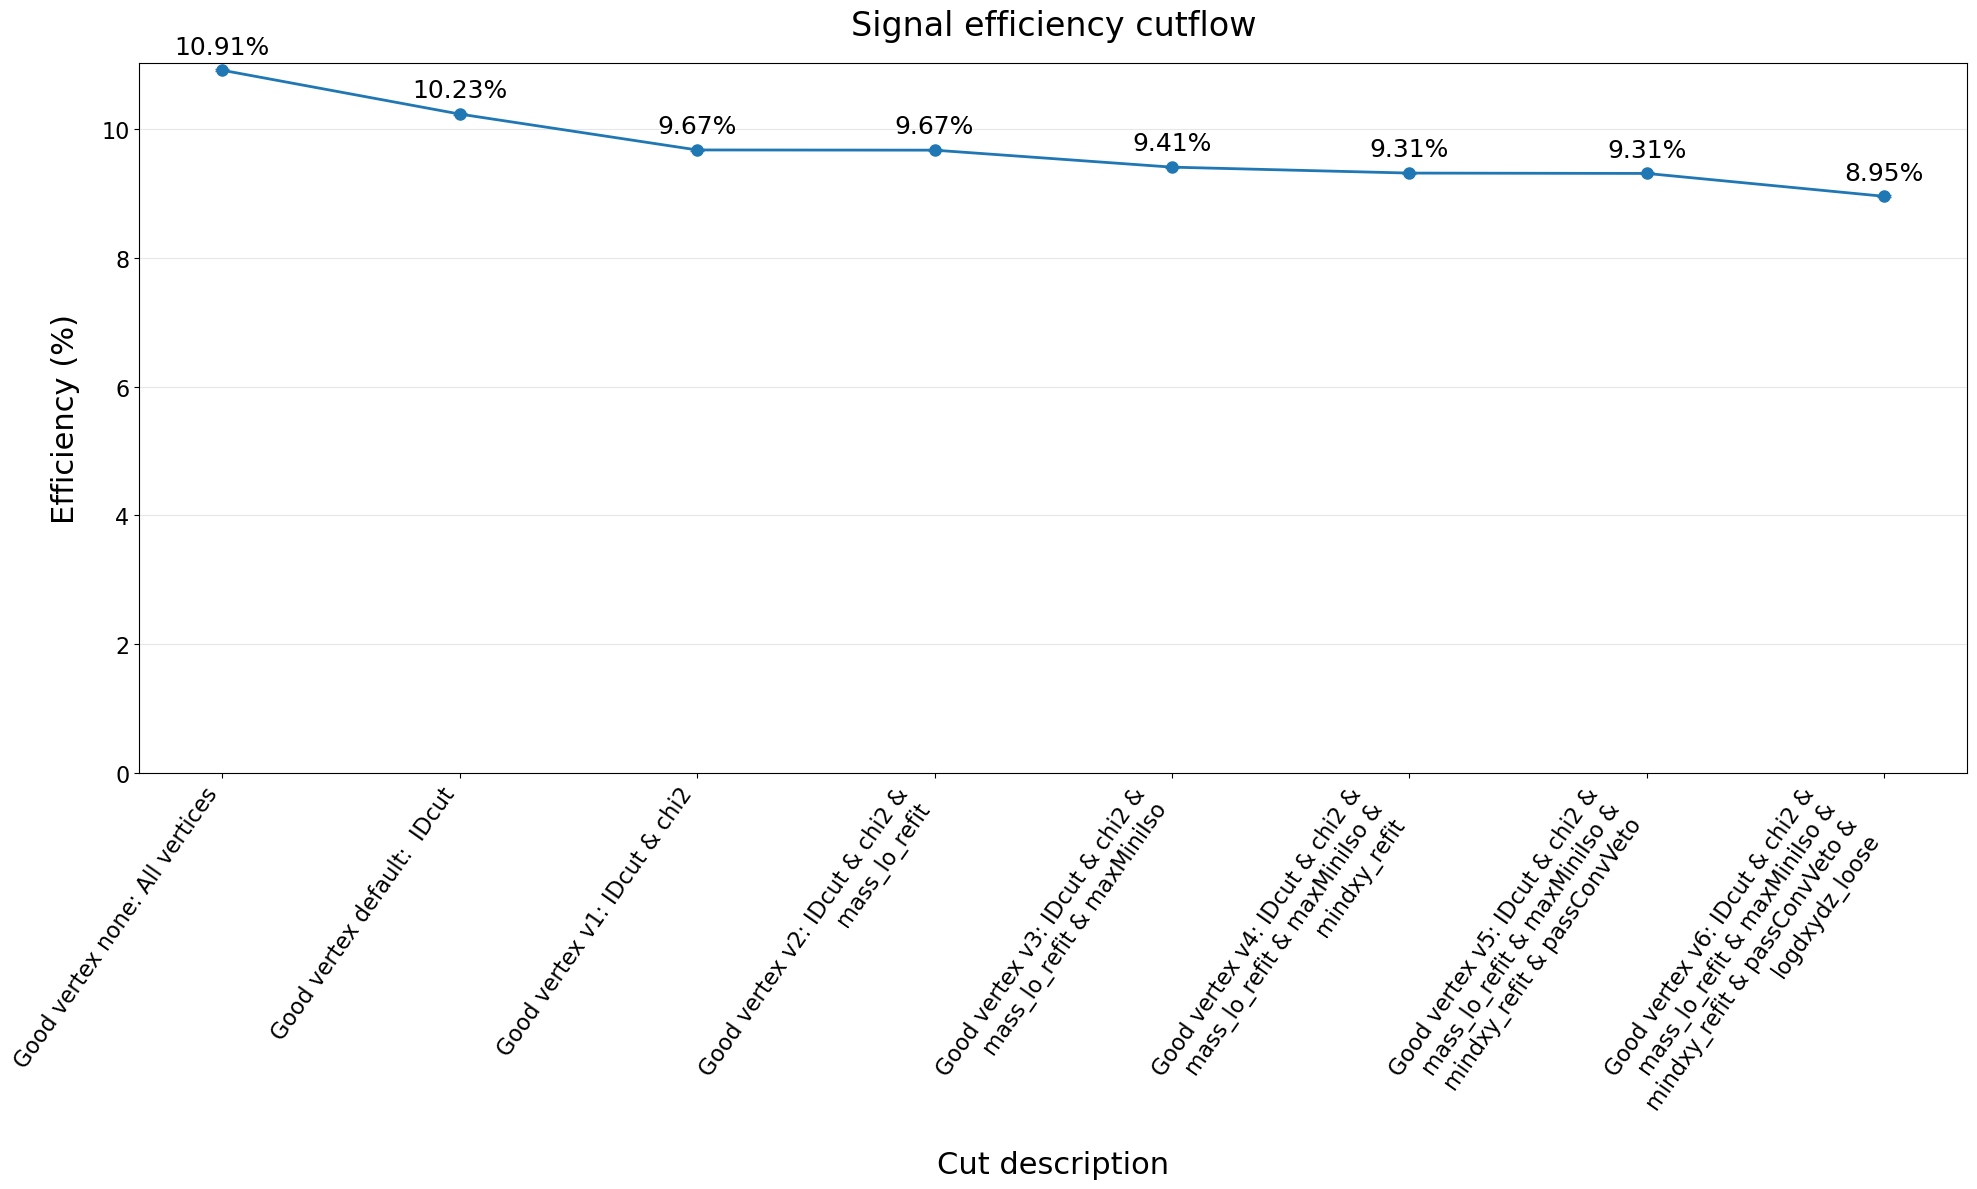

In [6]:
# Font sizes
title_size = 24
axis_label_size = 22
tick_size = 16
value_size = 18

x = np.arange(len(cutflow_df))
eff = cutflow_df['efficiency (%)'].to_numpy(dtype=float)
yerr = np.vstack([
    cutflow_df['uncertainty low (pp)'],
    cutflow_df['uncertainty high (pp)'],
])
valid = np.isfinite(eff) & np.all(np.isfinite(yerr), axis=0)

fig, ax = plt.subplots(figsize=(20, 12))

ax.plot(x, eff, color='tab:blue', linewidth=2)
ax.errorbar(
    x[valid], eff[valid],
    yerr=yerr[:, valid],
    fmt='o',
    color='tab:blue',
    markersize=8,
    capsize=5,
)

for pos, value in zip(x[valid], eff[valid]):
    ax.annotate(
        f'{value:.2f}%',
        (pos, value),
        xytext=(0, 12),
        textcoords='offset points',
        ha='center',
        fontsize=value_size,
    )

ax.set_xticks(x)
ax.set_xticklabels(
    [fill(descriptions[cut], width=32) for cut in cuts_to_plot],
    rotation=55,
    ha='right',
    fontsize=tick_size,
)
ax.tick_params(axis='y', labelsize=tick_size)

ax.set_xlabel('Cut description', fontsize=axis_label_size, labelpad=15)
ax.set_ylabel('Efficiency (%)', fontsize=axis_label_size, labelpad=15)
ax.set_title(
    f'Signal efficiency cutflow',
    fontsize=title_size,
    pad=20,
)

ax.set_ylim(bottom=0)
ax.margins(y=0.2)
ax.grid(axis='y', alpha=0.3)

fig.tight_layout()
plt.show()